# rand_orientation_gif.py

*Generated from `rand_orientation_gif.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
rand_orientation_gif.py - animated GIF, one frame per random surface.

Each frame draws surface s in the unrotated lattice (the crystal block and the
plane the step-1 deck turns into the surface), with its Miller label top left;
optionally the right half shows the rotated surface from above.  Angles come
from rand_angles_lammps.csv (the decks' random stream), or --surfaces-dat.

    python rand_orientation_gif.py                       # W, surfaces 1-50
    python rand_orientation_gif.py --mat WC --first 1 --last 20 --ms 800
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'rand_orientation_gif.py'
NB_OUT = "nb_figs"
ARGS = ["--mat", "W", "--first", "1", "--last", "30", "--out", NB_OUT]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image

import rand_geom as g
import rand_surface_views as v

In [3]:
# ============================ OPTIONS =====================================
MATERIAL = "W"            # "W" or "WC"
FRAME_FIRST = 1           # first random surface s
FRAME_LAST = 50           # last random surface s (inclusive)
FRAME_STEP = 1            # every n-th surface
MS_PER_FRAME = 1200       # display time per frame (ms); 1200 ms = 0.83 frames/s
HOLD_FIRST_MS = 2500      # longer pause on the first frame (ms)
REFERENCE_FRAMES = True   # low-index planes first: W (001),(011),(111); WC basal, prism, a-plane
SHOW_TOPVIEW = True       # right panel: top view of the rotated surface (what the He sees)
LOOP = 0                  # 0 = loop forever
DPI = 90                  # GIF resolution (90 dpi x 12 in = 1080 px wide)
FIGSIZE = (12.0, 5.6)     # inches; use (6.4, 5.6) with SHOW_TOPVIEW = False
SURFACES_DAT = None       # e.g. "rand_WC_surfaces.dat" to use the angles a run actually logged
OUT_DIR = "figs"

In [4]:
# ===========================================================================

# low-index references; small origin shifts keep lattice planes off the cut plane z = 0
# (a plane of atoms exactly at z = 0 is split by round-off; the decks' random origin avoids this)
REFS = {
    "W": [("(001) reference", (0, 0, 0, 0.05, 0.05, 0.05)), ("(011) reference", (0, 45, 0, 0.05, 0.05, 0.05)),
          ("(111) reference", (0, 54.7356, 45, 0.05, 0.05, 0.05))],
    "WC": [("basal reference, C-terminated", (0, 0, 0, 0.05, 0.05, 0.45)), ("prism reference", (0, 90, 0, 0.05, 0.05, 0.05)),
           ("a-plane reference", (0, 90, 90, 0.05, 0.05, 0.05))],
}


def render_frame(mat, title, angles, show_top):
    fig = plt.figure(figsize=FIGSIZE, dpi=DPI)
    if show_top:
        ax3 = fig.add_axes([0.0, 0.0, 0.5, 0.86], projection="3d")
        ax2 = fig.add_axes([0.53, 0.04, 0.44, 0.80])
    else:
        ax3 = fig.add_axes([0.0, 0.0, 1.0, 0.86], projection="3d")
    n = v.draw_block(ax3, mat, angles, show_regular=True)
    lab, dev = g.plane_label(mat, n)
    # ---- label, top-left corner
    fig.text(0.012, 0.975, "%s  %s%s" % (mat, "" if dev < 0.5 else "≈", lab), fontsize=20, weight="bold",
             va="top", ha="left", color="#1d3f8f",
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#1d3f8f", lw=1.2))
    fig.text(0.012, 0.865, "%s\nn = (%.2f, %.2f, %.2f)   β = %.0f°  γ = %.0f°"
             % (title, n[0], n[1], n[2], angles[1], angles[2]), fontsize=10.5, va="top", color="#333333")
    fig.text(0.25 if show_top else 0.5, 0.015, "unrotated crystal: blue plane = surface cut, orange = regular top face",
             ha="center", fontsize=9, color="#555555")
    if show_top:
        v.draw_topview(ax2, mat, angles, "top view after rotation (what the He sees)")
    fig.canvas.draw()
    img = Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])
    plt.close(fig)
    return img


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--mat", default=MATERIAL, choices=["W", "WC"])
    ap.add_argument("--first", type=int, default=FRAME_FIRST)
    ap.add_argument("--last", type=int, default=FRAME_LAST)
    ap.add_argument("--step", type=int, default=FRAME_STEP)
    ap.add_argument("--ms", type=int, default=MS_PER_FRAME, help="ms per frame")
    ap.add_argument("--no-refs", action="store_true", help="skip the low-index reference frames")
    ap.add_argument("--no-top", action="store_true", help="3D block only")
    ap.add_argument("--surfaces-dat", default=SURFACES_DAT)
    ap.add_argument("--out", default=OUT_DIR)
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    show_top = SHOW_TOPVIEW and not a.no_top

    frames, durs, src = [], [], set()
    if REFERENCE_FRAMES and not a.no_refs:
        for title, ang in REFS[a.mat]:
            frames.append(render_frame(a.mat, title, ang, show_top)); durs.append(a.ms)
    for s in range(a.first, a.last + 1, a.step):
        ang, sname = g.get_angles(s, a.surfaces_dat)
        src.add(sname)
        frames.append(render_frame(a.mat, "random surface %d" % s, ang, show_top)); durs.append(a.ms)
        print("frame s=%d (%s)" % (s, sname))
    durs[0] = max(durs[0], HOLD_FIRST_MS)
    # one shared 256-colour palette for every frame (no colour flicker between frames)
    w, h = frames[0].size
    sample = Image.new("RGB", (w, h * min(len(frames), 6)))
    for k, f in enumerate(frames[:: max(1, len(frames) // 6)][:6]):
        sample.paste(f, (0, k * h))
    ref = sample.quantize(colors=256, method=Image.MEDIANCUT)
    pal = [f.quantize(palette=ref, dither=Image.Dither.NONE) for f in frames]
    path = os.path.join(a.out, "rand_orientations_%s_s%d-%d.gif" % (a.mat, a.first, a.last))
    pal[0].save(path, save_all=True, append_images=pal[1:], duration=durs, loop=LOOP, optimize=True, disposal=2)
    print("wrote %s  (%d frames, %.1f MB; angles: %s)"
          % (path, len(pal), os.path.getsize(path) / 1e6, ", ".join(sorted(src))))

In [5]:
if __name__ == "__main__":
    main()

frame s=1 (LAMMPS stream)
frame s=2 (LAMMPS stream)


frame s=3 (LAMMPS stream)
frame s=4 (LAMMPS stream)


frame s=5 (LAMMPS stream)
frame s=6 (LAMMPS stream)


frame s=7 (LAMMPS stream)
frame s=8 (LAMMPS stream)


frame s=9 (LAMMPS stream)
frame s=10 (LAMMPS stream)


...

frame s=23 (LAMMPS stream)
frame s=24 (LAMMPS stream)


frame s=25 (LAMMPS stream)
frame s=26 (LAMMPS stream)


frame s=27 (LAMMPS stream)
frame s=28 (LAMMPS stream)


frame s=29 (LAMMPS stream)
frame s=30 (LAMMPS stream)


wrote nb_figs/rand_orientations_W_s1-30.gif  (33 frames, 2.0 MB; angles: LAMMPS stream)


In [6]:
# the same for WC
sys.argv = [SCRIPT, "--mat", "WC", "--first", "1", "--last", "30", "--out", NB_OUT]
main()

frame s=1 (LAMMPS stream)
frame s=2 (LAMMPS stream)


frame s=3 (LAMMPS stream)
frame s=4 (LAMMPS stream)


frame s=5 (LAMMPS stream)
frame s=6 (LAMMPS stream)


frame s=7 (LAMMPS stream)
frame s=8 (LAMMPS stream)


frame s=9 (LAMMPS stream)
frame s=10 (LAMMPS stream)


...

frame s=24 (LAMMPS stream)
frame s=25 (LAMMPS stream)


frame s=26 (LAMMPS stream)
frame s=27 (LAMMPS stream)


frame s=28 (LAMMPS stream)


frame s=29 (LAMMPS stream)
frame s=30 (LAMMPS stream)


wrote nb_figs/rand_orientations_WC_s1-30.gif  (33 frames, 2.6 MB; angles: LAMMPS stream)


## Outputs

In [7]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


rand_orientations_WC_s1-30.gif


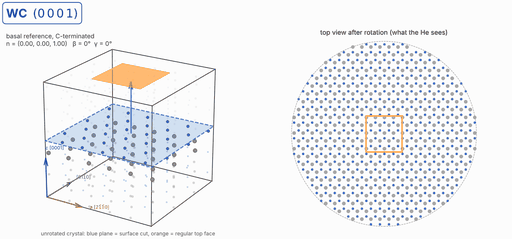

rand_orientations_W_s1-30.gif


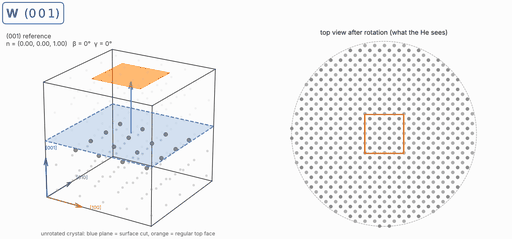

In [8]:
show(NB_OUT, ['*.gif'])